# 5 Advanced Visualizations

### 📊 What is the visualization about?
We want to create a shot chart for a given NHL team, showing the location of its shots on the ice to visualize shooting patterns and identify areas of offensive strength.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from ift6758.features.simple_visualizations import games_list
import plotly.graph_objects as go

- `number_games()` calculates the number of games played by each team during a given season.

In [4]:
def number_games(season) -> dict:
    # Get all the games dataframe
    df_games = games_list(season, events=False)

    # Keep regular season and playoffs only (game type code in the game id)
    df_games = df_games[df_games["game_type"].isin([2, 3])]

    # Calculate the number of game for each team
    number_games_per_team = {}
    for game in df_games.itertuples():
        homeTeam_id = getattr(game, "homeTeam_name")
        awayTeam_id = getattr(game, "awayTeam_name")
        number_games_per_team[homeTeam_id] = number_games_per_team.get(homeTeam_id, 0) + 1
        number_games_per_team[awayTeam_id] = number_games_per_team.get(awayTeam_id, 0) + 1

    return number_games_per_team

- `shot_data` contains all the information needed to generate the desired visualization. It returns a DataFrame containing, for each team, its name, the number of games played during the season, and the coordinates of every shot and goal recorded throughout the season.

In [84]:

def shot_data(season):
    """
    Gets the data from json (possibly by calling the distance function) for the season and extracts the shot coordinates to a more usable format
    :param season: 4 digit year of the season start
    :return: a dataframe containing each team's name, number of games, and an array of x,y shot coordinates (1 line per shot, columns x and y)
    """
    # Get each team's number of games
    team_game_number = number_games(season)

    # Link each team_id to its abbrev
    df_games = games_list(season, events=False)
    id_to_abbrev = {}
    for game in df_games.itertuples():
        id_to_abbrev[getattr(game, "homeTeam_id")] = getattr(game, "homeTeam_name")
        id_to_abbrev[getattr(game, "awayTeam_id")] = getattr(game, "awayTeam_name")

    # Get the shots and goals dataframe for the given season
    df_events = games_list(season)

    # Keep regular season and playoffs
    df_shots = df_events[
        df_events["game_type"].isin(["regular season", "playoffs"])
    ].copy()

    # Put all the shots on the same side (use same logic as distance() from simple_visualization.py)
    home_shoots = df_shots["team_id"] == df_shots["homeTeam_id"]
    attacks_left = np.where(
        home_shoots,
        df_shots["homeTeamDefendingSide"] == "right",
        df_shots["homeTeamDefendingSide"] == "left"
    )

    # Flip the shots by 180°­­­­ if they were taken from the left side of the pitch
    df_shots.loc[attacks_left, ["x_coord", "y_coord"]] *= -1

    rows = []
    for team_id, df_team in df_shots.groupby("team_id"):
        team = id_to_abbrev[team_id]
        rows.append({
            "team": team,
            "games": team_game_number[team],
            "shots": df_team[["x_coord", "y_coord"]].T
        })

    return pd.DataFrame(rows).T

#print(shot_data(2022).head())

In [85]:

def kde():
    """
    Calculates kde when given an array of shot coordinates
    :return: shot density
    """



In [220]:

class ShotMap:

    def __init__(self, season):
        """

        :param season: 4 digit year of the season start
        """
        self.season = season
        self.shots = shot_data(season)
        self.kdes = []

    def calculate_kdes1(self):
        """
        This calculates league average shot rate per hour (league_sph) and excess shot rate per hour for each team, in the form of shot density using kde. Also saves raw difference in shots per team hour
        :return:
        """
        # first, calculate kde for league average and save the factor, which will be given to the team kdes
        coords_league = np.ndarray(self.shots["shots"])
        print("LEAGUE COORDS: " + coords_league)
        #for team_coords in self.shots["shots"]:
        #    coords_league.append((team_coords["x_coord"], team_coords["y_coord"]))

        for team_coords in self.shots["shots"]:
            print(team_coords)
            coords_league.append(team_coords)

        self.league_kde = self.kdes.append(stats.gaussian_kde(pd.concat(coords_league)))
        factor = self.league_kde.covariance_factor()

        # calculate shot rate per hour density for each team using kde:
        for team_coords in self.shots["shots"]:
            self.kdes.append(stats.gaussian_kde(team_coords, bw_method=factor))

        # densities will need to be weighed by shot rate

        # convert teams' sph to excess sph using league average
        # calculate raw difference in shots per team hour
        self.shot_rate = []
        for team_coords in self.shots["shots"]:
            self.shot_rate.append(team_coords.shape[1])

    def calculate_kdes(self):
        """
        This calculates league average shot rate per hour (league_sph) and excess shot rate per hour for each team, in the form of shot density using kde. Also saves raw difference in shots per team hour
        :return:
        """
        # first, calculate kde for league average and save the factor, which will be given to the team kdes
        #for team_coords in self.shots["shots"]:
        #    coords_league.append((team_coords["x_coord"], team_coords["y_coord"]))

        self.league_kde = stats.gaussian_kde(pd.concat(self.shots.iloc[2,:].values, axis=1))
        factor = self.league_kde.covariance_factor()

        # calculate shot rate per hour density for each team using kde:
        for index, team in self.shots.items():
            self.kdes.append(stats.gaussian_kde(team["shots"].values, bw_method=factor))

        # densities will need to be weighed by shot rate

        # convert teams' sph to excess sph using league average
        # calculate raw difference in shots per team hour
        self.shot_rate = np.array([self.shots.shape[1],1], dtype=int)
        self.league_sn = 0
        self.league_hrs = 0
        for ind, team in self.shots.items():
            self.shot_rate[ind] = (team["shots"].values.shape[1] / (2*team["games"]) )
            self.league_sn += team["shots"].values.shape[1]
            self.league_hrs += (2*team["games"])
        print("league shot number " + str(self.league_sr))


In [221]:
shots2020 = ShotMap(2022)


In [219]:
print(shots2020.shots.shape[1])
for index, team in shots2020.shots.items():
    print(team["games"])
print("XXXXXX")
#print(shots2020.shots.iloc[2,:].values)
print(pd.concat(shots2020.shots.iloc[2,:].values, axis=1))
#x = stats.gaussian_kde(pd.concat([shots2020.shots.loc[:,2]]))


32
94
88
89
82
82
89
82
82
82
93
97
103
88
82
82
82
82
82
82
89
94
82
82
101
88
82
82
88
87
82
104
96
XXXXXX
         725    727    731    735    736    737    738    739    740    741    \
x_coord   75.0   62.0   80.0  -92.0   80.0   61.0   83.0   82.0   80.0   33.0   
y_coord   11.0   24.0  -18.0  -27.0   -5.0  -10.0   -4.0   -5.0   -1.0  -16.0   

         ...  86708  86711  86718  86721  86725  86726  86727  86728  86729  \
x_coord  ...   56.0   58.0   46.0   41.0   45.0   59.0   87.0   79.0   31.0   
y_coord  ...  -21.0  -22.0  -15.0  -13.0  -17.0  -37.0  -11.0    3.0   38.0   

         86730  
x_coord   34.0  
y_coord   32.0  

[2 rows x 88086 columns]


In [139]:
print(shots2020.shots.shape)
print(shots2020.shots)

print(shots2020.shots["shots"].values[0].shape)
for team_coords in shots2020.shots["shots"]:
            print(team_coords.shape[1])
for team_coords in shots2020.shots["shots"]:
    print(team_coords.shape)

print(shots2020.shots["shots"].array)

(3, 32)
                                                      0   \
team                                   New Jersey Devils   
games                                                 94   
shots           725    727    731    735    736    73...   

                                                      1   \
team                                  New York Islanders   
games                                                 88   
shots           859    860    861    862    865    86...   

                                                      2   \
team                                    New York Rangers   
games                                                 89   
shots           115    116    118    122    123    12...   

                                                      3   \
team                                 Philadelphia Flyers   
games                                                 82   
shots           724    726    728    729    730    73...   

                            

KeyError: 'shots'

In [222]:
shots2020.calculate_kdes()
shots2020.shots.head()
print(shots2020.kdes)

IndexError: too many indices for array: array is 0-dimensional, but 1 were indexed

In [152]:
print(shots2020.kdes)


[<scipy.stats._kde.gaussian_kde object at 0x0000026610A53E90>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A51210>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A52210>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A53190>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A53510>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A53090>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A50090>, <scipy.stats._kde.gaussian_kde object at 0x0000026610A53390>, <scipy.stats._kde.gaussian_kde object at 0x000002661A1D8210>, <scipy.stats._kde.gaussian_kde object at 0x00000266293D7810>, <scipy.stats._kde.gaussian_kde object at 0x000002660E474E90>, <scipy.stats._kde.gaussian_kde object at 0x000002660E474F50>, <scipy.stats._kde.gaussian_kde object at 0x000002660E476C10>, <scipy.stats._kde.gaussian_kde object at 0x000002660E477210>, <scipy.stats._kde.gaussian_kde object at 0x000002660E477510>, <scipy.stats._kde.gaussian_kde object at 0x000002664437B3D0>, <scipy.

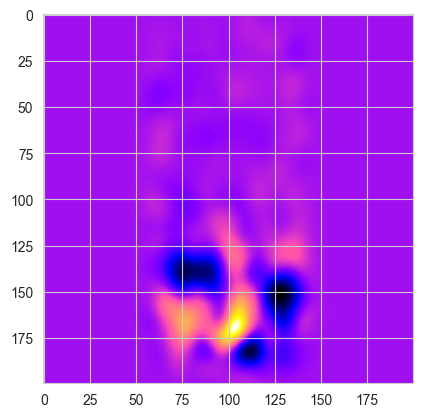

In [153]:
X, Y = np.mgrid[-100:100:200j, -100:100:200j]
positions = np.vstack([X.ravel(), Y.ravel()])
# différence entre deux équipes:
plt.imshow(np.reshape(shots2020.kdes[0](positions).T, X.shape) - np.reshape(shots2020.league_kde(positions).T, X.shape), cmap = "gnuplot2")
plt.show()

In [17]:
def interactive_shot_map(shot_map):
    """
    :param shot_map: ShotMap object
    :return: Creates html interactive figure ?
    """
    # checks if shot_map has kdes, if not, calls shot_map.calculate_kde()
    if len(shot_map.kdes) == 0:
        shot_map.calculate_kdes()

    df = shot_map.shots
    # For now not the right data
    coords = df["shots"][0] #For initialisation of the figure
    #coords = shot_map.kdes[0]
    team_list = df["team"].drop_duplicates()

    teams = []
    for i in range(len(team_list)):
        it = dict(label = team_list[i], args=[{"z": shot_map.kdes}], method="restyle")
        teams.append(it)

    # CODE TAKEN FROM PLOTLY DEMO
    # create figure
    fig = go.Figure()

    # Add surface trace
    fig.add_trace(go.Heatmap(z=coords.values.tolist(), colorscale="Viridis")) #TODO Changed code

    # Update plot sizing
    fig.update_layout(
        width=800,
        height=900,
        autosize=False,
        margin=dict(t=0, b=0, l=0, r=0),
        template="plotly_white",
    )

    # Update 3D scene options
    fig.update_scenes(
        aspectratio=dict(x=1, y=1, z=0.7),
        aspectmode="manual"
    )

    # Add dropdown
    fig.update_layout(
        updatemenus=[
            dict(
                buttons = teams, #Changed code here
                direction="down",
                pad={"r": 10, "t": 10},
                showactive=True,
                x=0.1,
                xanchor="left",
                y=1.1,
                yanchor="top"
            ),
        ]
    )

    # Add annotation
    fig.update_layout(
        annotations=[
            dict(text="Team:", showarrow=False,
            x=0, y=1.085, yref="paper", align="left")
        ]
    )

    # From demo in blog template
    # fig.write_html("../../figures/interactive_figure.html", include_plotlyjs="cdn", full_html=False)
    fig.show()

In [18]:
interactive_shot_map(shots2020)

TypeError: Object of type gaussian_kde is not JSON serializable